In [26]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244081123

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"

print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")


[Conda 环境] exp01
[学号]       20244081123
[机器指纹] 94bbc0242be151d1
[RUN_ID]   20244081123-94bbc0242be151d1


In [27]:
# bonjour

# ================= 实验 1：NumPy 数组、数据类型与索引 =================

# 1) 分别创建整数、浮点数和布尔值 ndarray
arr_int = np.array([1, 2, 3, 4])
arr_float = np.array([1.0, 2.5, 3.75])
arr_bool = np.array([True, False, True])

for label, arr in [("整数", arr_int), ("浮点数", arr_float), ("布尔值", arr_bool)]:
    print(f"{label}数组: {arr}, dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")


整数数组: [1 2 3 4], dtype=int64, shape=(4,), ndim=1
浮点数数组: [1.   2.5  3.75], dtype=float64, shape=(3,), ndim=1
布尔值数组: [ True False  True], dtype=bool, shape=(3,), ndim=1


**说明：NumPy 数组的数据类型与 Python 列表的差别**

- NumPy 数组的 `dtype` 是统一的：一个数组只能存放同一种类型（`int64`、`float64`、`bool` 等），
  创建时自动推断并统一；Python 列表可以混合存放任意类型（`[1, "a", 2.5]` 合法）。
- NumPy 数组带有 `shape`、`ndim` 等维度信息，元素在内存中连续存放，并支持向量化运算；
  Python 列表没有维度概念，做数值运算需要手动写循环。
- 因此 NumPy 数组更省内存、计算更快，是数值计算的基础；Python 列表更灵活。


In [28]:
# 2) 用 np.arange(12) 创建一维数组并改变形状
a1 = np.arange(12)
print("一维数组:", a1, "shape =", a1.shape)

a_3_4 = a1.reshape(3, 4)
a_2_3_2 = a1.reshape(2, 3, 2)

print("reshape(3, 4):")
print(a_3_4, a_3_4.shape)
print("reshape(2, 3, 2):")
print(a_2_3_2, a_2_3_2.shape)


一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11] shape = (12,)
reshape(3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]] (3, 4)
reshape(2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]] (2, 3, 2)


改变形状时，**各维度大小的乘积必须等于原数组的元素总数**（此处 `12 = 3×4 = 2×3×2`）。
只要 reshape 前后元素总数一致即可，否则会抛出 `ValueError`。


In [29]:
# 3) 对形状 (3, 4) 的数组做索引
mat = a_3_4
print("矩阵:\n", mat)

row_2 = mat[1]              # 第 2 行（按“第二行”理解，对应索引 1）
cols_1_3 = mat[:, 0:3]      # 第 1~3 列（索引 0、1、2）
gt6 = mat[mat > 6]          # 大于 6 的元素

print("\n第 2 行:", row_2, "shape =", row_2.shape)
print("第 1~3 列:\n", cols_1_3, "shape =", cols_1_3.shape)
print("大于 6 的元素:", gt6, "shape =", gt6.shape)


矩阵:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行: [4 5 6 7] shape = (4,)
第 1~3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape = (3, 3)
大于 6 的元素: [ 7  8  9 10 11] shape = (5,)


In [30]:
# 4) 逻辑选元素：小于 2 或大于 7 / 大于 3 且小于 7
nums = np.arange(10)

mask_or = (nums < 2) | (nums > 7)
mask_and = (nums > 3) & (nums < 7)
print("小于 2 或大于 7（|）:", nums[mask_or])
print("大于 3 且小于 7（&）:", nums[mask_and])

print("小于 2 或大于 7（np.logical_or）:", nums[np.logical_or(nums < 2, nums > 7)])
print("大于 3 且小于 7（np.logical_and）:", nums[np.logical_and(nums > 3, nums < 7)])


小于 2 或大于 7（|）: [0 1 8 9]
大于 3 且小于 7（&）: [4 5 6]
小于 2 或大于 7（np.logical_or）: [0 1 8 9]
大于 3 且小于 7（np.logical_and）: [4 5 6]


In [31]:
# 5) 逐元素乘法与矩阵乘法
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("*       :\n", A * B)
print("multiply:\n", np.multiply(A, B))
print("@       :\n", A @ B)
print("matmul  :\n", np.matmul(A, B))


*       :
 [[ 5 12]
 [21 32]]
multiply:
 [[ 5 12]
 [21 32]]
@       :
 [[19 22]
 [43 50]]
matmul  :
 [[19 22]
 [43 50]]


`*` 与 `np.multiply()` 是**逐元素乘法**（Hadamard 积）：对应位置元素相乘，形状不变；
`@` 与 `np.matmul()` 是**矩阵乘法**：结果第 i 行第 j 列 = 左矩阵第 i 行与右矩阵第 j 列的点积，形状按 (m×n)·(n×p)→(m×p) 变化。
例如 `A @ B` 的第 1 行第 1 列 = 1×5 + 2×7 = 19，而 `A * B` 的第 1 行第 1 列 = 1×5 = 5。


## 实验 2：随机抽样、统计与缺失值

In [32]:
np.random.seed(42)  # 固定随机种子，保证结果可复现

# 1) 生成 1000 个均值为 70、标准差为 10 的模拟成绩，并裁剪到 0~100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数:", scores.size)
print("最小值:", scores.min())
print("最大值:", scores.max())
print("均值:  ", scores.mean())
print("标准差:", scores.std())
print("极差:  ", scores.max() - scores.min())


样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值:   70.18400443523215
标准差: 9.755086339034765
极差:   62.41267340069073


In [33]:
# 2) 从 1~10 不放回抽 5 个：均匀抽样 vs 按整数大小成比例加权抽样
pool = np.arange(1, 11)

uniform = np.random.choice(pool, size=5, replace=False)
print("均匀抽样:", uniform)

weights = pool / pool.sum()   # 数值越大的整数权重越高
print("权重:", np.round(weights, 3))
weighted = np.random.choice(pool, size=5, replace=False, p=weights)
print("加权抽样:", weighted)


均匀抽样: [ 4  9  2  6 10]
权重: [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182]
加权抽样: [10  2  8  9  6]


In [34]:
# 3) permutation（保留原数组） vs shuffle（原地打乱）
arr = np.arange(1, 6)
print("permutation 前原数组:", arr)
arr_perm = np.random.permutation(arr)   # 返回新数组，原数组保持不变
print("permutation 结果:    ", arr_perm)
print("permutation 后原数组:", arr)       # 仍是 [1 2 3 4 5]

arr2 = np.arange(1, 6)
print("shuffle 前:", arr2)
np.random.shuffle(arr2)                 # 原地打乱，直接修改原数组
print("shuffle 后:", arr2)


permutation 前原数组: [1 2 3 4 5]
permutation 结果:     [5 1 3 2 4]
permutation 后原数组: [1 2 3 4 5]
shuffle 前: [1 2 3 4 5]
shuffle 后: [1 5 2 4 3]


In [35]:
# 4) 缺失值 np.nan 的影响
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan    # 第 10、20、30 个值（索引 9、19、29）

print("普通均值:       ", np.mean(scores_nan))
print("忽略缺失值均值: ", np.nanmean(scores_nan))
print("缺失值个数:     ", np.isnan(scores_nan).sum())


普通均值:        nan
忽略缺失值均值:  70.19620743160239
缺失值个数:      3


`np.nan` 是特殊的浮点“非数”，任何与它参与的算术运算结果都是 `nan`，因此 `np.mean()`、`np.sum()` 等普通统计函数会被整体“污染”为 `nan`。
需要改用 `np.nanmean()`、`np.nansum()` 等忽略缺失值的函数，或先剔除 `nan` 元素再统计。


In [36]:
# 5) 将含缺失值的成绩整理成内存中的表格变量，供实验 4 直接使用（不写磁盘）
score_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})
print(score_table.head())


   序号         成绩
0   1  74.967142
1   2  68.617357
2   3  76.476885
3   4  85.230299
4   5  67.658466


## 实验 3：SciPy 数值计算与 Matplotlib 可视化

In [37]:
%matplotlib inline
import scipy.linalg as sla
import scipy.optimize as opt
import scipy.stats as stats
import matplotlib.pyplot as plt

# 设置中文字体，保证图表标题与坐标轴标签正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


In [38]:
# 1) 解线性方程组 3x + y = 9, x + 2y = 8
A = np.array([[3, 1], [1, 2]], dtype=float)
b = np.array([9, 8], dtype=float)

sol = sla.solve(A, b)
print("解: x =", sol[0], ", y =", sol[1])
print("NumPy 代入验证 A @ sol =", A @ sol, "（应等于", b, "）")


解: x = 2.0 , y = 3.0
NumPy 代入验证 A @ sol = [9. 8.] （应等于 [9. 8.] ）


In [39]:
# 2) 求方程 x^2 - 2 = 0 的正根和负根
f = lambda x: x ** 2 - 2

r_pos = opt.root(f, x0=1.5)
r_neg = opt.root(f, x0=-1.5)

print("正根: x =", r_pos.x[0], ", 成功 =", r_pos.success, ", f(x) =", f(r_pos.x))
print("负根: x =", r_neg.x[0], ", 成功 =", r_neg.success, ", f(x) =", f(r_neg.x))


正根: x = 1.4142135623730951 , 成功 = True , f(x) = [4.4408921e-16]
负根: x = -1.4142135623730951 , 成功 = True , f(x) = [4.4408921e-16]


In [40]:
# 3) 求 f(x) = x^2 + 2x + 2 的最小值
g = lambda x: x ** 2 + 2 * x + 2
res = opt.minimize(g, x0=0.0)

print("极小点: x =", res.x[0], ", 函数值 =", res.fun)
print("解析结果: 极小点 x = -1, 最小值 = 1")


极小点: x = -1.00000000944232 , 函数值 = 1.0
解析结果: 极小点 x = -1, 最小值 = 1


In [41]:
# 4) 两组独立样本的 t 检验
np.random.seed(0)
group1 = np.random.normal(0, 1, 100)
group2 = np.random.normal(1, 1, 100)

t_stat, p_value = stats.ttest_ind(group1, group2)
print("t 统计量 =", t_stat)
print("p 值     =", p_value)
if p_value < 0.05:
    print("结论: p < 0.05，拒绝原假设，两组均值存在显著差异")
else:
    print("结论: p >= 0.05，不能拒绝原假设，两组均值无显著差异")


t 统计量 = -7.04142736901327
p 值     = 3.0598200945140844e-11
结论: p < 0.05，拒绝原假设，两组均值存在显著差异


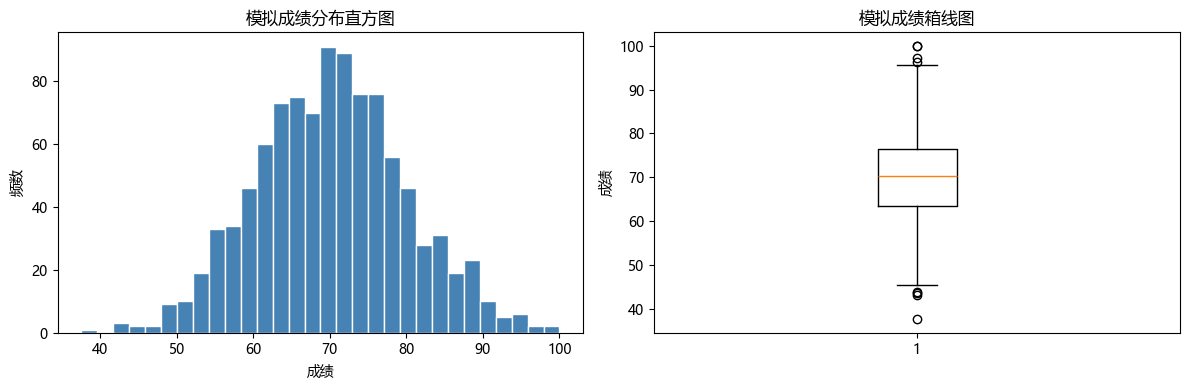

In [42]:
# 5a) 实验 2 的有效成绩：直方图 + 箱线图
valid_scores = scores_nan[~np.isnan(scores_nan)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(valid_scores, bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("模拟成绩分布直方图")
axes[0].set_xlabel("成绩")
axes[0].set_ylabel("频数")

axes[1].boxplot(valid_scores)
axes[1].set_title("模拟成绩箱线图")
axes[1].set_ylabel("成绩")

plt.tight_layout()
plt.show()


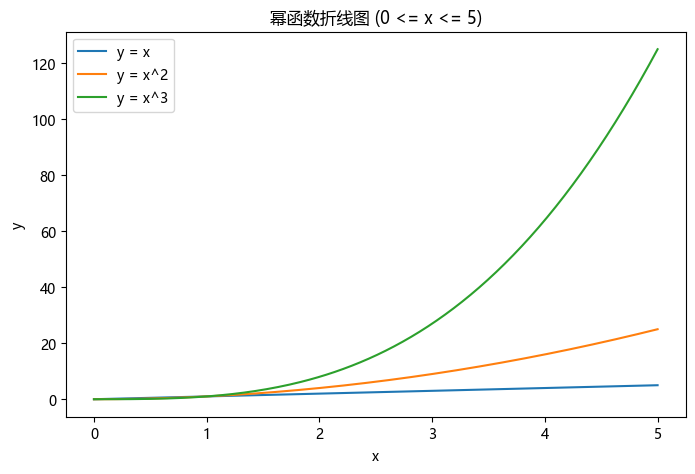

In [43]:
# 5b) y = x, y = x^2, y = x^3 在 [0, 5] 上的折线图
x = np.linspace(0, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(x, x, label="y = x")
plt.plot(x, x ** 2, label="y = x^2")
plt.plot(x, x ** 3, label="y = x^3")
plt.title("幂函数折线图 (0 <= x <= 5)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


## 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写

In [44]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")   # 行索引为姓名

subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)         # 三科总分
df["Average"] = df[subjects].mean(axis=1)      # 三科平均分

print("行索引:", df.index.tolist())
print("列名:  ", df.columns.tolist())
print("前 3 行:\n", df.head(3))
print("基本统计信息:\n", df.describe())


行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名:   ['Group', 'Math', 'English', 'Python', 'Total', 'Average']
前 3 行:
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333
基本统计信息:
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [45]:
# 2) 用 loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学生
print("loc['Carol']:\n", df.loc["Carol"])
print("iloc[2]（Carol 是第 3 行，索引 2）:\n", df.iloc[2])

print("\n平均分 >= 80 的学生:\n", df[df["Average"] >= 80][["Group", "Average"]])


loc['Carol']:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc[2]（Carol 是第 3 行，索引 2）:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 >= 80 的学生:
       Group    Average
Name                  
Alice     A  91.000000
Carol     B  88.333333
Eva       A  85.666667
Frank     B  81.000000


In [46]:
# 3) 列均值 axis=0 与每名学生行均值 axis=1
print("三科列均值 (axis=0):\n", df[subjects].mean(axis=0))
print("\n每名学生行均值 (axis=1):\n", df[subjects].mean(axis=1))


三科列均值 (axis=0):
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生行均值 (axis=1):
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [47]:
# 4) apply 求三科最高分；agg 一次得到每科 min/mean/max；rank 排名
df["Max"] = df[subjects].apply(np.max, axis=1)
print("每名学生三科最高分:\n", df[subjects + ["Max"]].head(6))

print("\n每科 min / mean / max:\n", df[subjects].agg(["min", "mean", "max"]))

print("\nPython 成绩降序排名 (rank):\n", df["Python"].rank(ascending=False))


每名学生三科最高分:
        Math  English  Python  Max
Name                             
Alice    88       90      95   95
Bob      72       68      80   80
Carol    91       85      89   91
David    65       73      70   73
Eva      79       92      86   92
Frank    84       77      82   84

每科 min / mean / max:
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Python 成绩降序排名 (rank):
 Name
Alice    1.0
Bob      5.0
Carol    2.0
David    6.0
Eva      3.0
Frank    4.0
Name: Python, dtype: float64


In [48]:
# 5) 按 Group 分组统计人数与平均分；再用 transform('mean') 增加组内 Python 平均分
print("每组人数:\n", df.groupby("Group").size())
print("\n每组三科平均分:\n", df.groupby("Group")[subjects].mean())

df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print("\n组内 Python 平均分:\n", df[["Group", "Python", "GroupPythonMean"]])


每组人数:
 Group
A    3
B    3
dtype: int64

每组三科平均分:
             Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

组内 Python 平均分:
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [49]:
# 6) filter：保留 Python 平均分不低于 80 的组
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)

print("保留的组:", sorted(kept["Group"].unique().tolist()))
print(kept[["Group", "Python", "GroupPythonMean"]])


保留的组: ['A', 'B']
      Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [50]:
# 7) 协方差矩阵与皮尔森相关系数矩阵
cov_mx = df[subjects].cov()
corr_mx = df[subjects].corr(method="pearson")

print("协方差矩阵:\n", cov_mx)
print("\n皮尔森相关系数矩阵:\n", corr_mx)


协方差矩阵:
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔森相关系数矩阵:
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


以 **Math 与 English** 为例：两者协方差为正，说明两科成绩同向变化（数学高的学生英语也倾向偏高）；
相关系数越接近 1，正线性相关越强；接近 0 表示基本无线性关系；为负则表示反向变化。
本例中 Math 与 English 的相关系数明显为正且较大，说明两科成绩高度正相关。
